<a href="https://colab.research.google.com/github/ms24191-PN/IDC-AQIupgrade/blob/main/EDA_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loading the data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

AQI_Data = '/content/drive/MyDrive/AQI_data.csv'
data = pd.read_csv(AQI_Data)

Mounted at /content/drive


# Visualize city-wise AQI

## City-wise AQI

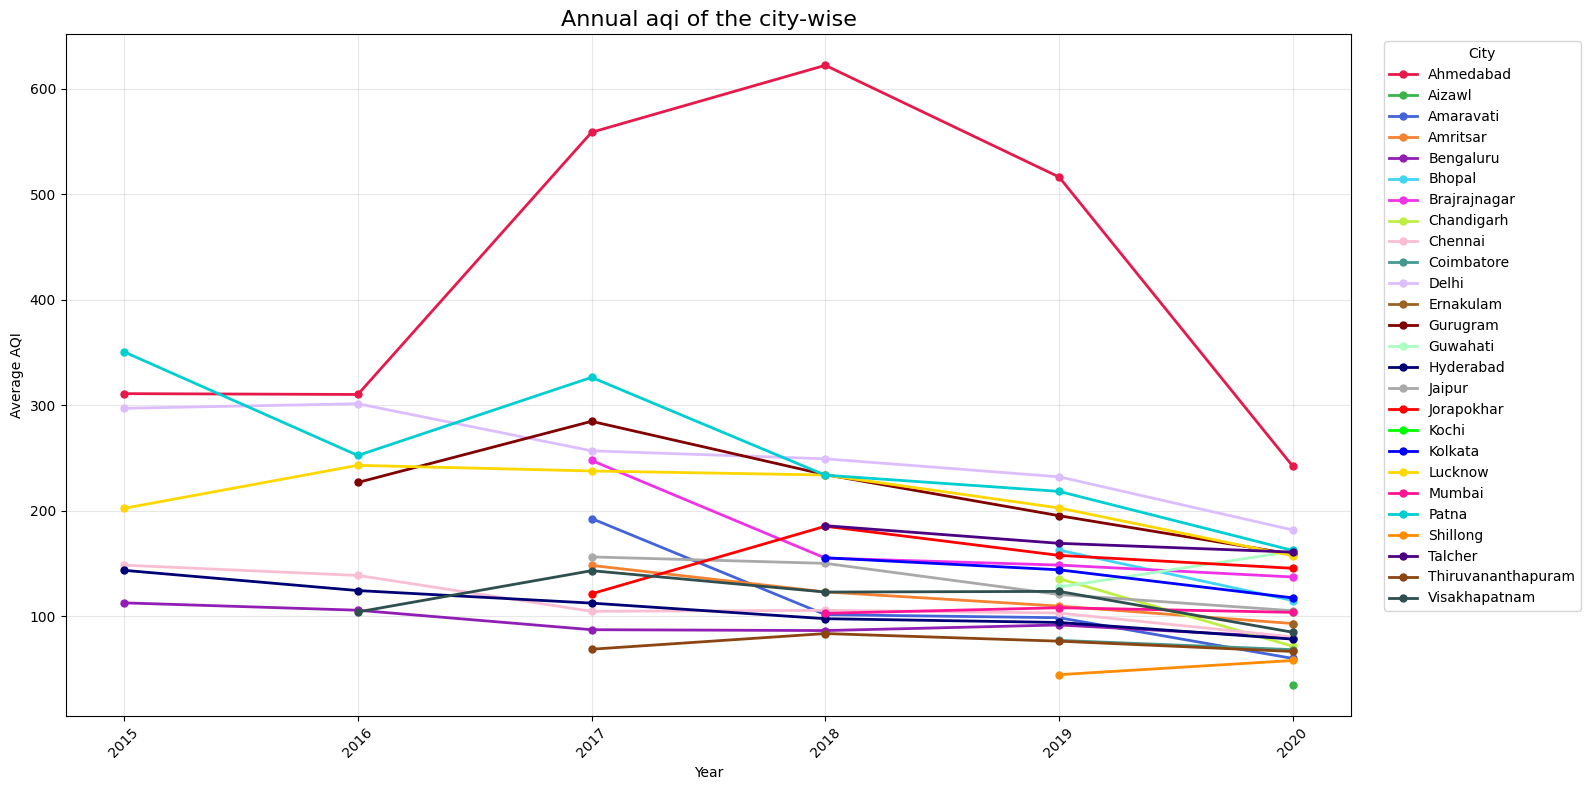

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#let's calculate the average aqi of the year
avg_year_aqi = (data.groupby(['City','Year'])['AQI'].mean().reset_index())

cities = sorted(avg_year_aqi['City'].unique())
colors = [
    "#E6194B", "#3CB44B", "#4363D8", "#F58231",
    "#911EB4", "#42D4F4", "#F032E6", "#BFEF45",
    "#FABED4", "#469990", "#DCBEFF", "#9A6324",
    "#800000", "#AAFFC3", "#000075", "#A9A9A9",
    "#FF0000", "#00FF00", "#0000FF", "#FFD700",
    "#FF1493", "#00CED1", "#FF8C00", "#4B0082",
    "#8B4513", "#2F4F4F"
]
plt.figure(figsize = (16,8))

for city , color in zip(cities, colors):
  city_data = avg_year_aqi[avg_year_aqi['City'] == city].sort_values('Year')
  plt.plot(city_data['Year'], city_data['AQI'], marker = 'o', linewidth =2, markersize = 5, label= city, color = color)

plt.title('Annual aqi of the city-wise', fontsize = 16)
plt.xlabel('Year')
plt.ylabel('Average AQI')

plt.xticks(sorted(avg_year_aqi['Year'].unique()), rotation = 45)
plt.legend(title = 'City', bbox_to_anchor = (1.02,1), loc ='upper left')
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

For top 10 Cities


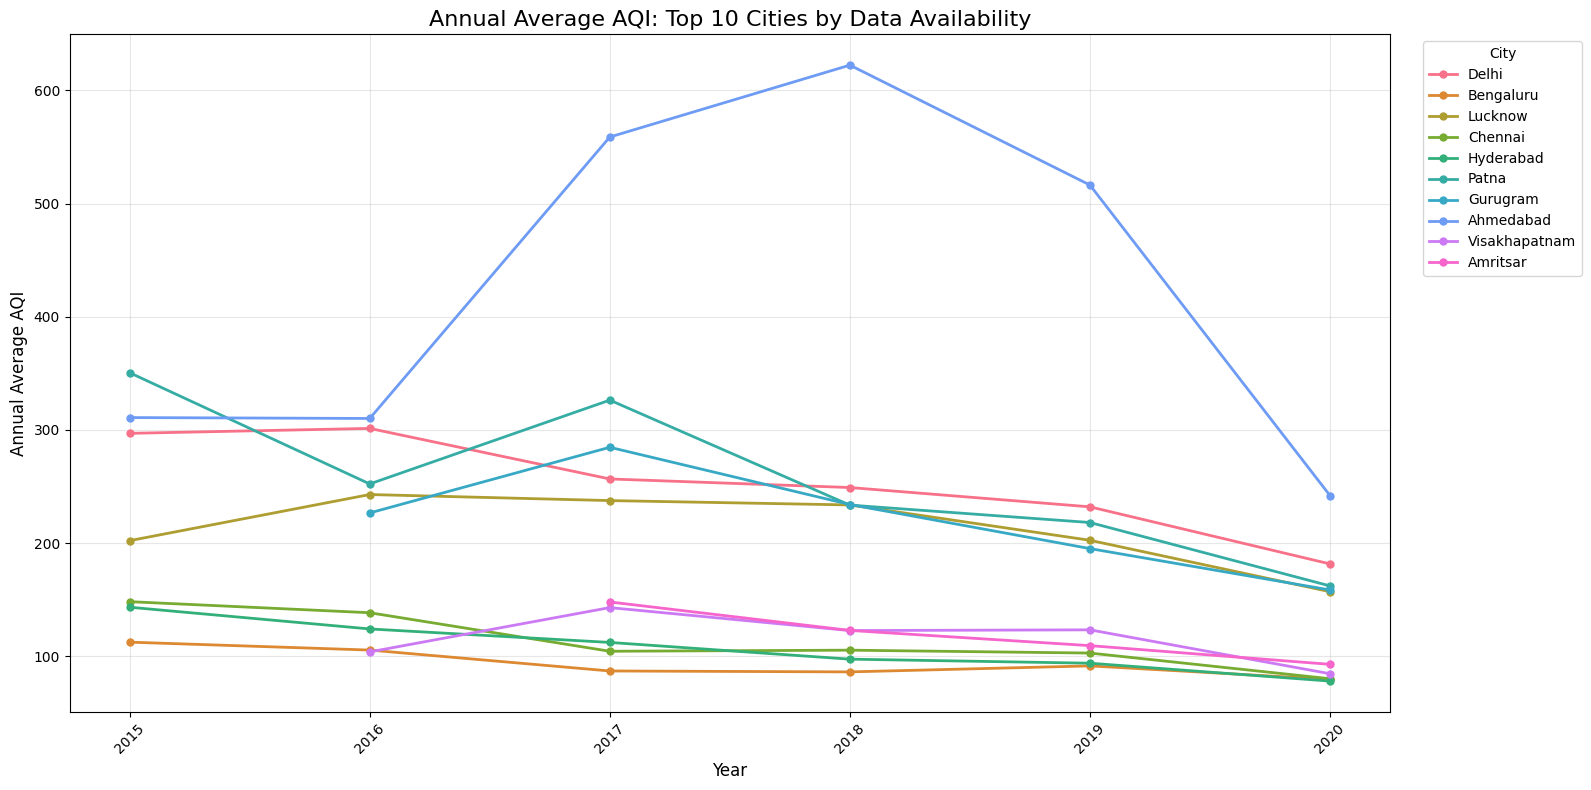

AQI Ranking of the Top 10 Cities


,City,Data_Points,Average_AQI
0,Ahmedabad,1334,452.12
1,Delhi,1999,259.49
2,Patna,1459,240.78
3,Gurugram,1453,225.12
4,Lucknow,1893,217.97
5,Amritsar,1126,119.92
6,Visakhapatnam,1171,117.27
7,Chennai,1884,114.50
8,Hyderabad,1880,109.21
9,Bengaluru,1910,94.32


Cities with the Highest and Lowest Average AQI


,Category,City,Average AQI,Data Points
0,Highest Average AQI,Ahmedabad,452.12,1334
1,Lowest Average AQI,Bengaluru,94.32,1910


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count available AQI data points for each city
city_counts = (data.dropna(subset=['AQI']).groupby('City')['AQI'].count().sort_values(ascending=False))

#Select top 10 cities with most AQI data points
top_10_cities = city_counts.head(10).index.tolist()

#Filtering data for selected cities
top_data = data[data['City'].isin(top_10_cities)].copy()

#Calculate annual average AQI for each city
yearly_avg_aqi = (top_data.groupby(['City', 'Year'])['AQI'].mean().reset_index())

#Plot all 10 cities in a single graph
colors = sns.color_palette('husl', n_colors=len(top_10_cities))

plt.figure(figsize=(16, 8))

for city, color in zip(top_10_cities, colors):

    city_data = yearly_avg_aqi[yearly_avg_aqi['City'] == city].sort_values('Year')

    plt.plot(
        city_data['Year'],
        city_data['AQI'],
        marker='o',
        linewidth=2,
        markersize=5,
        label=city,
        color=color
    )

plt.title('Annual Average AQI: Top 10 Cities by Data Availability',fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Annual Average AQI', fontsize=12)

plt.xticks(sorted(yearly_avg_aqi['Year'].unique()),rotation=45)
plt.legend(title='City',bbox_to_anchor=(1.02, 1),loc='upper left')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 4. Calculate overall average AQI for each selected city
city_avg_aqi = (top_data.groupby('City').agg(Data_Points=('AQI', 'count'),Average_AQI=('AQI', 'mean')).reset_index())

# Rank cities by average AQI
city_avg_aqi = city_avg_aqi.sort_values('Average_AQI',ascending=False).reset_index(drop=True)

city_avg_aqi['Average_AQI'] = city_avg_aqi['Average_AQI'].round(2)

# Display the complete ranking table
print("AQI Ranking of the Top 10 Cities")
display(city_avg_aqi)

# 5. Identify the highest and lowest average AQI cities
highest_aqi_city = city_avg_aqi.loc[city_avg_aqi['Average_AQI'].idxmax()]

lowest_aqi_city = city_avg_aqi.loc[city_avg_aqi['Average_AQI'].idxmin()]

# Create summary table
summary_table = pd.DataFrame([
    {
        'Category': 'Highest Average AQI',
        'City': highest_aqi_city['City'],
        'Average AQI': highest_aqi_city['Average_AQI'],
        'Data Points': highest_aqi_city['Data_Points']
    },
    {
        'Category': 'Lowest Average AQI',
        'City': lowest_aqi_city['City'],
        'Average AQI': lowest_aqi_city['Average_AQI'],
        'Data Points': lowest_aqi_city['Data_Points']
    }
])

print("Cities with the Highest and Lowest Average AQI")
display(summary_table)

For Mumbai , Bengaluru, and Delhi

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


# Filter dates and cities
cities = ['Delhi', 'Bengaluru', 'Chennai',
          'Hyderabad', 'Mumbai', 'Chandigarh']

plot_data = data[data['City'].isin(cities) & data['Date'].between('2019-09-03', '2020-07-01')].dropna(subset=['Date', 'AQI']).copy()

plot_data = plot_data.sort_values('Date')

# Plot all available data points
plt.figure(figsize=(16, 8))

for city in cities:
    city_data = plot_data[plot_data['City'] == city]

    plt.plot(
        city_data['Date'],
        city_data['AQI'],
        marker='o',
        markersize=3,
        linewidth=1.5,
        label=city
    )

plt.title('AQI Trends Across Six Cities (Sep 2019 – Jul 2020)', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('AQI', fontsize=12)
plt.legend(title='City')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


# Define cities and date range
cities = ['Delhi', 'Bengaluru', 'Chennai',
    'Hyderabad', 'Mumbai', 'Chandigarh']

start_date = pd.Timestamp('2019-09-03')
end_date = pd.Timestamp('2020-07-01')

# Filter data
data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
plot_data = data[data['City'].isin(cities) & data['Date'].between(start_date, end_date)].dropna(subset=['Date', 'AQI']).copy()

# Create Year-Month column and calculate monthly average AQI
plot_data['Month'] = plot_data['Date'].dt.to_period('M')

monthly_aqi = (plot_data.groupby(['City', 'Month'])['AQI'].mean().reset_index())

# Converting Month to datetime for plotting the data
monthly_aqi['Month'] = monthly_aqi['Month'].dt.to_timestamp()

# Defining the colors
colors = {
    'Delhi': '#E6194B',
    'Bengaluru': '#3CB44B',
    'Chennai': '#4363D8',
    'Hyderabad': '#F58231',
    'Mumbai': '#911EB4',
    'Chandigarh': '#D55E00'
}

# Plot monthly average AQI
plt.figure(figsize=(15, 7))

for city in cities:
    city_data = monthly_aqi[monthly_aqi['City'] == city].sort_values('Month')

    plt.plot(
        city_data['Month'],
        city_data['AQI'],
        marker='o',
        linewidth=2,
        markersize=5,
        label=city,
        color=colors[city]
    )

plt.title('Monthly Average AQI for Six Cities ''(Sep 2019 – Jul 2020)',fontsize=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Monthly Average AQI', fontsize=12)

plt.xticks(
    monthly_aqi['Month'].drop_duplicates().sort_values(),
    monthly_aqi['Month'].drop_duplicates().sort_values().dt.strftime('%b %Y'),
    rotation=45
)

plt.legend(title='City')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pollutant correlations

Pollutant

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select pollutant features
pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
    'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene'
]

# Create box plot
plt.figure(figsize=(14, 7))

sns.boxplot(data=data[pollutants])

plt.title('Box Plot of Pollutant Features', fontsize=16)
plt.xlabel('Pollutant', fontsize=12)
plt.ylabel('Concentration', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
    'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene'
]


pollutant_data = data[pollutants].copy()


correlation_matrix = pollutant_data.corr(method='pearson')

# Plotting the correlation heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title('Correlation Analysis Among Air Pollutants', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Yearly / Monthly Trends

Without averaging the month

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

cities = sorted(data['City'].unique())
years = sorted(data['Year'].unique())


year_colors = dict(
    zip(years, sns.color_palette('husl', n_colors=len(years)))
)

# Use a leap year - so that February 29th is valid
reference_year = 2020

# Create a common date using the actual month and day
data['Plot_Date'] = pd.to_datetime(
    str(reference_year) + '-' +
    data['Month'].astype(str).str.zfill(2) + '-' +
    data['Day'].astype(str).str.zfill(2)
)

for city in cities:

    # Select the city
    city_data = data[data['City'] == city].copy()

    plt.figure(figsize=(16, 8))

    for year in years:

        # Selecting the year
        year_data = city_data[city_data['Year'] == year].copy()

        if len(year_data) == 0:
            continue

        # Sort from January to December
        year_data = year_data.sort_values('Plot_Date')

        # Ploting actual daily AQI
        plt.plot(
            year_data['Plot_Date'],
            year_data['AQI'],
            label=str(year),
            color=year_colors[year],
            linewidth=1
        )

    plt.title(f'Daily AQI Across Years - {city}')
    plt.xlabel('Month')
    plt.ylabel('AQI')

    # January to December ticks for uniform date
    month_positions = pd.date_range(start=f'{reference_year}-01-01',end=f'{reference_year}-12-01',freq='MS')

    month_labels = ['January', 'February', 'March', 'April',
        'May', 'June', 'July', 'August',
        'September', 'October', 'November', 'December']

    plt.xticks(month_positions,month_labels,rotation=45)

    # Start exactly at January and end at December
    plt.xlim(pd.Timestamp(f'{reference_year}-01-01'),pd.Timestamp(f'{reference_year}-12-31'))

    plt.legend(title='Year',bbox_to_anchor=(1.02, 1),loc='upper left')

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

With averging the month

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create month from the original Date column
#data['Month'] = data['Date'].dt.month

# Calculating monthly AQI for each city and year
monthly_aqi = (data.groupby(['City', 'Year', 'Month'])['AQI'].mean().reset_index())

# Getting cities and years
cities = sorted(monthly_aqi['City'].unique())
years = sorted(monthly_aqi['Year'].unique())

# Creating a different color for each year
year_colors = dict(zip(years, sns.color_palette('husl', n_colors=len(years))))

# Month names
month_labels = ['January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December']

# Ploting one graph for each cities
for city in cities:

    city_data = monthly_aqi[monthly_aqi['City'] == city].copy()

    plt.figure(figsize=(14, 7))

    for year in years:

        year_data = city_data[city_data['Year'] == year].sort_values('Month')

        if len(year_data) == 0:
            continue

        plt.plot(year_data['Month'],year_data['AQI'],marker='o',linewidth=2,label=str(year),color=year_colors[year])

    plt.title(f'Monthly AQI Across Years - {city}')
    plt.xlabel('Month')
    plt.ylabel('AQI')

    plt.xticks(range(1, 13),month_labels,rotation=45)

    plt.xlim(1, 12)

    plt.legend(title='Year',bbox_to_anchor=(1.02, 1),loc='upper left')

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
print(data.columns)

# **City wise Comparison**

# (Delhi vs Chandigarh vs Mumbai)

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

AQI_Data = '/content/drive/MyDrive/AQI_data.csv'
data = pd.read_csv(AQI_Data)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Yearly Comparison

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

compare_cities = ['Delhi', 'Chandigarh', 'Mumbai']
compare_df = data[data['City'].isin(compare_cities)].copy()

# Yearly average AQI per city
yearly_avg = (compare_df.groupby(['City', 'Year'])['AQI']
                       .mean()
                       .reset_index())

plt.figure(figsize=(10, 6))
for city in compare_cities:
    cd = yearly_avg[yearly_avg['City'] == city].sort_values('Year')
    plt.plot(cd['Year'], cd['AQI'], marker='o', linewidth=2.5,
             markersize=8, label=city)

plt.title('Yearly Average AQI: Delhi vs Chandigarh vs Mumbai', fontsize=14)
plt.xlabel('Year'); plt.ylabel('Average AQI')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("📊 Yearly AQI Comparison:")
display(yearly_avg.pivot(index='Year', columns='City', values='AQI').round(2))


# Seasonal AQI comparison

In [ ]:
seasonal = (compare_df.groupby(['City', 'Season'])['AQI']
                     .mean()
                     .reset_index())

plt.figure(figsize=(10, 6))
sns.barplot(x='Season', y='AQI', hue='City', data=seasonal,
            palette='Set2')
plt.title('Average AQI by Season — City Comparison', fontsize=14)
plt.xlabel('Season'); plt.ylabel('Average AQI')
plt.legend(title='City')
plt.tight_layout(); plt.show()

# Pollutant comparison across cities

In [ ]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3']

pollutant_avg = (compare_df.groupby('City')[pollutants]
                          .mean()
                          .round(2))

print("📊 Average Pollutant Levels per City (µg/m³ or mg/m³):")
display(pollutant_avg)

# Normalize for fair comparison (each pollutant divided by its max)
normalized = pollutant_avg.div(pollutant_avg.max())

plt.figure(figsize=(12, 6))
normalized.T.plot(kind='bar', figsize=(12, 6),
                   color=['crimson', 'steelblue', 'seagreen'])
plt.title('Pollutant Levels Compared Across Cities (Normalized)',
          fontsize=14)
plt.xlabel('Pollutant'); plt.ylabel('Relative Level (0–1)')
plt.xticks(rotation=0)
plt.legend(title='City')
plt.tight_layout(); plt.show()

# Monthly trends

In [ ]:
monthly = (compare_df.groupby(['City', 'Month'])['AQI']
                     .mean()
                     .reset_index())

plt.figure(figsize=(12, 6))
for city in compare_cities:
    cd = monthly[monthly['City'] == city].sort_values('Month')
    plt.plot(cd['Month'], cd['AQI'], marker='o', linewidth=2.5,
             markersize=8, label=city)

plt.title('Monthly AQI Pattern (2019-2020 avg)', fontsize=14)
plt.xlabel('Month'); plt.ylabel('Average AQI')
plt.xticks(range(1, 13))
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# (Chennai vs Hyderabad vs Bengaluru)

# Yearly Comparison

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

compare_cities = ['Chennai', 'Hyderabad', 'Bengaluru']
compare_df = data[data['City'].isin(compare_cities)].copy()

# Yearly average AQI per city
yearly_avg = (compare_df.groupby(['City', 'Year'])['AQI']
                       .mean()
                       .reset_index())

plt.figure(figsize=(10, 6))
for city in compare_cities:
    cd = yearly_avg[yearly_avg['City'] == city].sort_values('Year')
    plt.plot(cd['Year'], cd['AQI'], marker='o', linewidth=2.5,
             markersize=8, label=city)

plt.title('Yearly Average AQI: Chennai vs Hyderabad vs Bengaluru', fontsize=14)
plt.xlabel('Year'); plt.ylabel('Average AQI')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("📊 Yearly AQI Comparison:")
display(yearly_avg.pivot(index='Year', columns='City', values='AQI').round(2))

# Seasonal AQI comparison

In [ ]:
seasonal = (compare_df.groupby(['City', 'Season'])['AQI']
                     .mean()
                     .reset_index())

plt.figure(figsize=(10, 6))
sns.barplot(x='Season', y='AQI', hue='City', data=seasonal,
            palette='Set2')
plt.title('Average AQI by Season — City Comparison', fontsize=14)
plt.xlabel('Season'); plt.ylabel('Average AQI')
plt.legend(title='City')
plt.tight_layout(); plt.show()

# Pollutant comparison across cities

In [ ]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3']

pollutant_avg = (compare_df.groupby('City')[pollutants]
                          .mean()
                          .round(2))

print("📊 Average Pollutant Levels per City (µg/m³ or mg/m³):")
display(pollutant_avg)

# Normalize for fair comparison (each pollutant divided by its max)
normalized = pollutant_avg.div(pollutant_avg.max())

plt.figure(figsize=(12, 6))
normalized.T.plot(kind='bar', figsize=(12, 6),
                   color=['crimson', 'steelblue', 'seagreen'])
plt.title('Pollutant Levels Compared Across Cities (Normalized)',
          fontsize=14)
plt.xlabel('Pollutant'); plt.ylabel('Relative Level (0–1)')
plt.xticks(rotation=0)
plt.legend(title='City')
plt.tight_layout(); plt.show()

# Monthly trends

In [ ]:
monthly = (compare_df.groupby(['City', 'Month'])['AQI']
                     .mean()
                     .reset_index())

plt.figure(figsize=(12, 6))
for city in compare_cities:
    cd = monthly[monthly['City'] == city].sort_values('Month')
    plt.plot(cd['Month'], cd['AQI'], marker='o', linewidth=2.5,
             markersize=8, label=city)

plt.title('Monthly AQI Pattern (2019-2020 avg)', fontsize=14)
plt.xlabel('Month'); plt.ylabel('Average AQI')
plt.xticks(range(1, 13))
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()